# Which Servo Failure Can a Walking Robot Survive?

Faults on the left knee servo, set through FMU parameters, and the copper loss of every servo.

[Setup and files](README.md).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
from common import *  # noqa: F403  FMU and MuJoCo helpers, plot style

%matplotlib inline

In [2]:
CASES = {
    "Healthy": {},
    "Left knee, 6° play": {"kneeBacklash": np.radians(6)},
    "Left knee at 3.7 V": {"kneeSupply": 3.7},
    "Left knee unpowered": {"kneeGain": 0},
}
runs = {name: walk_fmu(**parameters) for name, parameters in CASES.items()}  # about a minute each

In [3]:
def copper_loss(df):
    late = df["time"] >= 2
    return (RESISTANCE * cols(df, "motorCurrent")[late] ** 2).mean(0)

rows = []
for name, df in runs.items():
    fallen = df["time"][df["trunkHeight"] < 0.09]
    loss = copper_loss(df)
    rows.append({"case": name, "speed [m/s]": np.nan if len(fallen) else speed(df),
                 "falls at [s]": fallen.iloc[0] if len(fallen) else np.nan,
                 "lowest trunk [mm]": np.nan if len(fallen) else 1e3 * df["trunkHeight"].min(),
                 "copper loss [W]": np.nan if len(fallen) else loss.sum(),
                 "right knee loss [W]": np.nan if len(fallen) else loss[12]})
pd.DataFrame(rows).set_index("case").round(3)

,speed [m/s],falls at [s],lowest trunk [mm],copper loss [W],right knee loss [W]
case,,,,,
Healthy,0.138,NaN,111.057,1.740,0.407
"Left knee, 6° play",0.134,NaN,110.306,1.765,0.412
Left knee at 3.7 V,0.132,NaN,109.829,1.823,0.489
Left knee unpowered,NaN,0.687,NaN,NaN,NaN


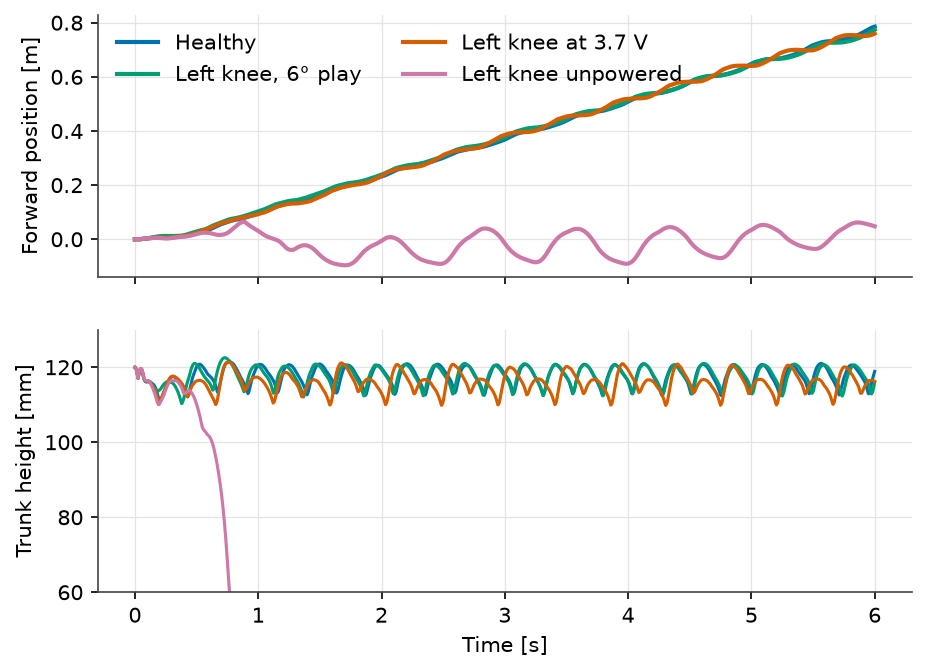

In [4]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
for (name, df), c in zip(runs.items(), [BLUE, GREEN, ORANGE, PINK]):
    a1.plot(df["time"], df["distance"], color=c, label=name)
    a2.plot(df["time"], 1e3 * df["trunkHeight"], color=c, lw=1.5)
a1.set_ylabel("Forward position [m]"); a1.legend(ncol=2)
a2.set_ylabel("Trunk height [mm]"); a2.set_ylim(60, 130); a2.set_xlabel("Time [s]")
plt.show()

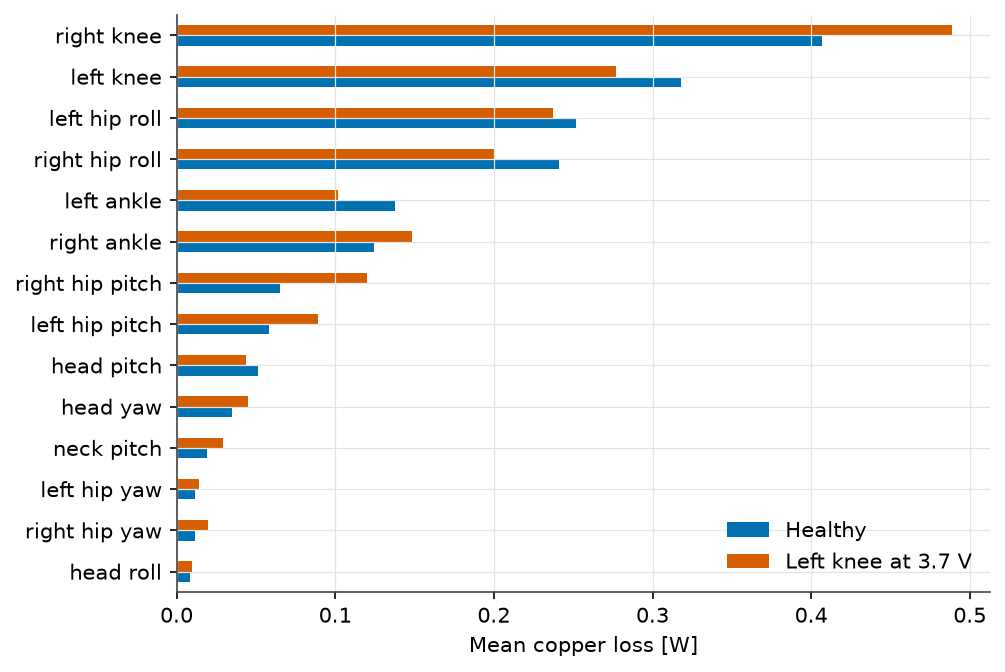

In [5]:
losses = pd.DataFrame({name: copper_loss(runs[name]) for name in ("Healthy", "Left knee at 3.7 V")}, index=JOINTS)
ax = losses.sort_values("Healthy").plot.barh(color=[BLUE, ORANGE], figsize=(7, 5))
ax.set_xlabel("Mean copper loss [W]")
plt.show()